In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta, time
import random


In [102]:
df = pd.read_excel("C:/Users/samsa/Downloads/Practice_Data.xlsx")

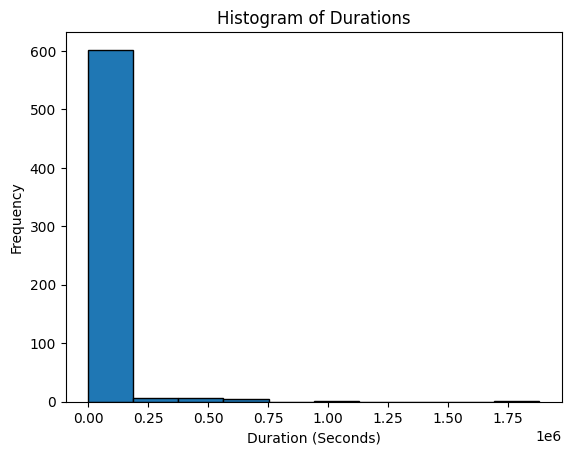

In [103]:
df["diff"] = pd.to_timedelta(df["end"]-df["start"]).dt.total_seconds()
plt.hist(df['diff'], bins=10, edgecolor='black')
plt.xlabel('Duration (Seconds)')
plt.ylabel('Frequency')
plt.title('Histogram of Durations')
plt.show()

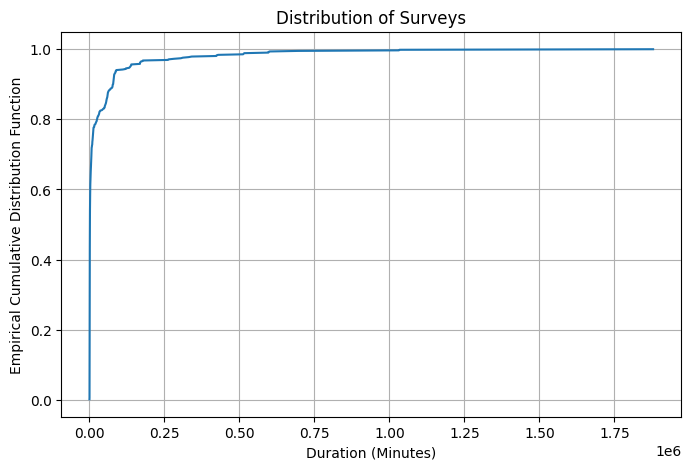

In [104]:
q25, q75 = np.percentile(df['diff'], [25, 75])
values = df['diff']
x = np.sort(values)
y = np.arange(1, len(values) + 1) / len(values)

plt.figure(figsize=(8,5))
plt.plot(x,y)
plt.xlabel("Duration (Minutes)")
plt.ylabel("Empirical Cumulative Distribution Function")
plt.title("Distribution of Surveys")
plt.grid(True)

In [105]:
Q1 = df["diff"].quantile(0.25)
Q3 = df["diff"].quantile(0.75)
IQR = Q3 - Q1
df["too_fast"] = (df["diff"] < Q1 - 1.5*IQR)
df["too_slow"] = (df["diff"] > Q3 + 1.5*IQR)


In [7]:
rows=600
enums = ["Sam", "Phillip", "Hamse", "Giorgio", "Ben", "Aya", "Adri", "Tyler"]


In [8]:
def random_start_time(day, month, year):
    day = day
    month = month
    year = year
    hour = random.randint(6,23)
    minute = random.randint(0,59)
    second = random.randint(0, 59)
    return datetime(year, month, day, hour, minute, second)

def random_end_time(start):
    mean = 1000
    std_dev = 200
    value = -1
    while value <= 0:
        value = np.random.normal(loc=mean, scale=std_dev)
    
    total_seconds = int(round(value))
    return start + timedelta(seconds = total_seconds)
    

In [9]:
data = []

for i in range(28, 31):
    for j in range(rows):
        enum = random.choice(enums)
        start_time = random_start_time(i, 11, 2025)
        if round(np.random.rand()) == 1:
            start_sec_1 = random_end_time(start_time)
            end_sec_1 = random_end_time(start_sec_1)
            start_sec_2 = end_sec_1
        else:
            start_sec_1 = np.nan
            end_sec_1 = np.nan
            start_sec_2 = random_end_time(start_time)
        end_sec_2 = random_end_time(start_sec_2)
        end_time = random_end_time(end_sec_2)

        data.append([enum, start_time, start_sec_1, end_sec_1, start_sec_2, end_sec_2, end_time])

df = pd.DataFrame(data, columns=[
    "enumerators", "Start Time", "Start Section 1", "End Section 1", "Start Section 2", "End Section 2", "End Time"])

df.to_csv("tylerpractice_data2.csv")

    

In [107]:
df = pd.read_csv("C:/Users/samsa/Downloads/practice_data2.csv")

In [ ]:
sections = df.columns[3:-1]
section_cols = {}


1
2
3
4


In [ ]:
qc_table = {}
hist_paths = []
ecdf_paths = []
unique_enums = []

